# 06 · Results: forecast comparison

**Purpose.** Score the six models one year ahead, draw Fig. 4 and compute the comparisons between models.

**Approximate runtime.** Under 30 seconds.

**Paper section served.** IV-B Results: forecast comparison.

**Inputs**

- `data/interim/forecasts.parquet` from notebook 05.

**Paper artifacts**

- `results/tables/table3.csv`: Table III, pinball loss and coverage of the six models on the daytime low, annual and monthly.
- `results/figures/fig4` (PNG at 600 dpi and PDF): Fig. 4, the actual annual daytime low against the probability of exceedance (POE) bands of M2, M3, M4 and M5.
- `results/tables/headline_numbers.csv`: the four comparisons between models, on the daytime low and on the whole-day minimum.

**Supporting checks** (`results/checks`)

- `table3_minimum.csv`: the same scores on the whole-day minimum, which the paper mentions in a sentence.
- `check_poe50_bias.csv`: the mean error of POE50 by model, on both targets, annual and monthly.

**Main process**

1. Set up.
2. Table III: scores by model on the daytime low.
3. Check: the same scores on the whole-day minimum.
4. Fig. 4: annual forecasts of the daytime low against the actuals.
5. The headline comparisons.
6. Check: the bias of POE50.
7. Result.

**What is judged where.** H1 (M3 against M2) and H2 (M4 against M3) are judged on the **daytime low**, annual and monthly. The whole-day minimum is the headline forecast target; the same comparisons are shown for it as secondary. This was fixed before any model was run.

**M6 is supplementary.** M6 (XGBoost with M3's information) was added after the scores of M1 to M5 had been seen, so that M5 against M6 shows what weather adds in tree form. It does not replace H2, which stays M4 against M3.

**Seven annual points.** Each model is scored on seven test years (2019 to 2025), so the annual scores rest on seven points; the monthly scores rest on 76 or 77.

**How to read the scores.**

- **Pinball loss** (MW) is the score for a POE forecast; lower is better. A forecast is penalised for each MW it is off, more heavily on the side it is meant to be rarely wrong on. The value reported for a model is the mean over its POE10, POE50 and POE90 forecasts and over the test points.
- **Coverage** is the share of actuals that fell between POE90 and POE10. A well-calibrated band holds the actual about 80% of the time. With seven annual points coverage moves in steps of 14 percentage points, so it is descriptive only.

Earlier figures made from these forecasts (the POE bands with three panels and on the whole-day minimum, and the monthly pinball loss by calendar month) are in `exploration/01_conference/A2_superseded_figures.ipynb`.

## 1. Set up

In [1]:
import pandas as pd

from pynmdf import evaluate, plots
from pynmdf.config import load_config

cfg = load_config()
interim, figures, tables, checks = (
    cfg["dirs"][key] for key in ("interim", "figures", "tables", "checks")
)
plots.set_style()

pd.set_option("display.width", 220, "display.max_columns", 30)
pd.set_option("display.float_format", "{:,.1f}".format)
forecasts = pd.read_parquet(interim / "forecasts.parquet")

# The two targets with reported comparisons. H1 and H2 are judged on the first.
REPORTED = ["daytime_low", "minimum"]
reported = forecasts[forecasts["target"].isin(REPORTED)]

# The columns of a score table shown on screen; the saved files hold every column.
levels, names = ("annual", "monthly"), ("pinball_mean", "coverage", "points")
SHOWN = [f"{level}_{name}" for level in levels for name in names]

## 2. Table III: scores by model on the daytime low

One row per model; the columns give the annual scores and then the monthly scores. `points` is the number of test points scored: seven years, and the months that have enough valid data.

The saved CSV also holds the pinball loss at each POE level separately.

In [2]:
table3 = evaluate.score_table(forecasts, "daytime_low")
table3.to_csv(tables / "table3.csv")
table3[SHOWN]

,annual_pinball_mean,annual_coverage,annual_points,monthly_pinball_mean,monthly_coverage,monthly_points
model,,,,,,
M1,63.1,0.4,7,50.5,0.6,77
M2,34.6,1.0,7,53.5,0.7,77
M3,43.3,0.7,7,49.6,0.6,77
M4,67.5,0.6,7,46.2,0.7,77
M5,28.5,0.7,7,42.8,0.7,77
M6,36.6,0.9,7,75.1,0.5,77


## 3. Check: the same scores on the whole-day minimum

The whole-day minimum is the headline forecast target, but H1 and H2 are judged on the daytime low, so Table III reports the daytime low. The scores on the whole-day minimum are kept as a check, in the same layout, for the sentence in which the paper mentions them.

In [3]:
table3_minimum = evaluate.score_table(forecasts, "minimum")
table3_minimum.to_csv(checks / "table3_minimum.csv")
table3_minimum[SHOWN]

,annual_pinball_mean,annual_coverage,annual_points,monthly_pinball_mean,monthly_coverage,monthly_points
model,,,,,,
M1,45.2,0.1,7,43.5,0.4,76
M2,31.1,1.0,7,37.5,0.7,76
M3,41.6,0.7,7,41.4,0.6,76
M4,61.5,0.6,7,41.5,0.6,76
M5,26.9,0.7,7,32.5,0.6,76
M6,28.0,0.9,7,42.2,0.6,76


## 4. Fig. 4: annual forecasts of the daytime low against the actuals

Four panels on one y-axis: M2 (time trend, no rooftop photovoltaic capacity, PV), M3 (PV only), M4 (PV plus weather, linear) and M5 (PV plus weather, XGBoost). The shaded band runs from POE90 to POE10, the line is POE50 and the dots are the actual values.

The table under the figure is its data.

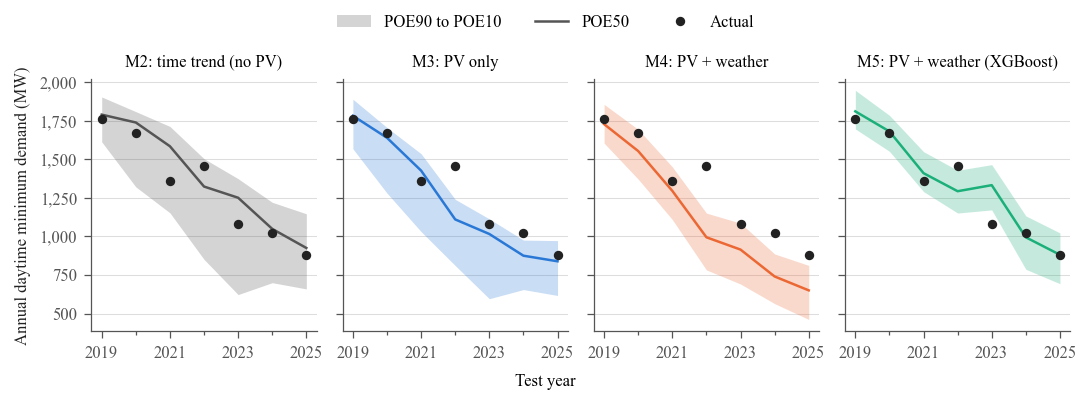

In [4]:
panels = ["M2", "M3", "M4", "M5"]
annual = forecasts[(forecasts["target"] == "daytime_low") & (forecasts["level"] == "annual")]
figure = plots.poe_bands(annual, panels, "Annual daytime minimum demand (MW)")
plots.save_figure(figure, figures, "fig4")

In [5]:
drawn = annual[annual["model"].isin(panels)]
bands = drawn.pivot(index="year", columns="model", values=["poe90", "poe50", "poe10"])
bands = bands.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
bands.insert(0, ("", "actual"), drawn.groupby("year")["actual"].first())
bands.round()

model              M2                      M3                      M4                      M5                
       actual   poe90   poe50   poe10   poe90   poe50   poe10   poe90   poe50   poe10   poe90   poe50   poe10
year                                                                                                         
2019  1,759.0 1,613.0 1,789.0 1,904.0 1,568.0 1,782.0 1,889.0 1,605.0 1,728.0 1,856.0 1,696.0 1,810.0 1,947.0
2020  1,671.0 1,321.0 1,738.0 1,809.0 1,281.0 1,639.0 1,705.0 1,371.0 1,553.0 1,693.0 1,552.0 1,680.0 1,785.0
2021  1,357.0 1,153.0 1,584.0 1,713.0 1,031.0 1,426.0 1,536.0 1,109.0 1,295.0 1,451.0 1,291.0 1,410.0 1,549.0
2022  1,458.0   851.0 1,323.0 1,504.0   811.0 1,110.0 1,240.0   783.0   994.0 1,151.0 1,151.0 1,293.0 1,428.0
2023  1,080.0   623.0 1,251.0 1,374.0   596.0 1,016.0 1,113.0   691.0   915.0 1,086.0 1,172.0 1,332.0 1,465.0
2024  1,019.0   700.0 1,049.0 1,221.0   656.0   875.0   976.0   564.0   740.0   886.0   787.0   994.0 1,133.0
2025    880.0   660.0   925.0 1,147.0   617.0   839.0   973.0   462.0   650.0   812.0   693.0   881.0 1,023.0

## 5. The headline comparisons

Four comparisons, each as the mean pinball loss of one model against another:

- **H1, PV against time:** M3 against M2.
- **H2, weather on top of PV:** M4 against M3.
- **Model form:** M5 (XGBoost) against M4 (linear), with the same information.
- **Supplementary, weather in tree form:** M5 against M6, both XGBoost, with and without the weather. Added after the scores were seen; it is not a test fixed in advance.

`change_pct` is negative when the first model scores better than the second. The daytime low is the target the hypotheses are judged on; the whole-day minimum is shown beside it.

In [6]:
headline = evaluate.compare(reported, evaluate.COMPARISONS)
headline.to_csv(tables / "headline_numbers.csv")
headline

model reference  model_pinball_mw  reference_pinball_mw  difference_mw  change_pct
comparison                          target      level                                                                                     
H1: PV against time                 daytime_low annual     M3        M2              43.3                  34.6            8.7        25.0
                                                monthly    M3        M2              49.6                  53.5           -3.9        -7.4
                                    minimum     annual     M3        M2              41.6                  31.1           10.6        34.1
                                                monthly    M3        M2              41.4                  37.5            3.9        10.3
H2: weather on top of PV            daytime_low annual     M4        M3              67.5                  43.3           24.2        56.0
                                                monthly    M4        M3              46.2                  49.6           -3.4        -6.9
                                    minimum     annual     M4        M3              61.5                  41.6           19.8        47.7
                                                monthly    M4        M3              41.5                  41.4            0.1         0.2
Model form: XGBoost against linear  daytime_low annual     M5        M4              28.5                  67.5          -39.0       -57.8
                                                monthly    M5        M4              42.8                  46.2           -3.3        -7.2
                                    minimum     annual     M5        M4              26.9                  61.5          -34.6       -56.2
                                                monthly    M5        M4              32.5                  41.5           -9.0       -21.6
Supplementary: weather in tree form daytime_low annual     M5        M6              28.5                  36.6           -8.1       -22.2
                                                monthly    M5        M6              42.8                  75.1          -32.3       -43.0
                                    minimum     annual     M5        M6              26.9                  28.0           -1.1        -4.0
                                                monthly    M5        M6              32.5                  42.2           -9.7       -23.0

## 6. Check: the bias of POE50

The mean error of each model's POE50 over its valid test points: actual minus forecast, in MW. Positive means the model's forecasts sat too low on average; negative, too high. Pinball loss mixes bias and spread, so this table shows the bias on its own.

It is the check behind two cautions. M4's forecasts sit too low, which notebook 05 traces to its PV x solar term. And a tree model cannot extrapolate PV capacity (notebook 05, section 5): M6 has no other input that moves with PV, so its monthly forecasts of the daytime low sit well above the actuals, and part of M5's margin over M6 is that handicap rather than the weather.

In [7]:
bias = evaluate.poe50_bias(reported, ["target", "level", "model"]).unstack("model")
bias.to_csv(checks / "check_poe50_bias.csv")
bias.round()

model                   M1     M2    M3    M4    M5     M6
target      level                                         
daytime_low annual  -126.0  -62.0  77.0 193.0 -25.0  -49.0
            monthly  -90.0 -140.0 -34.0  32.0 -61.0 -132.0
minimum     annual  -101.0  -65.0  54.0 162.0   0.0  -41.0
            monthly  -75.0  -86.0 -34.0  16.0  -8.0  -34.0

## 7. Result

The scores behind the results section, in one place: every model's mean pinball loss on both targets, and the comparisons on the target the hypotheses are judged on.

In [8]:
losses = evaluate.score(reported, ["target", "level", "model"])["pinball_mean"].unstack("model")
print("Mean pinball loss (MW) by target and level:")
print(losses.round(1).to_string())
print()
columns = ["model_pinball_mw", "reference_pinball_mw", "change_pct"]
judged = headline.xs("daytime_low", level="target")[columns]
print("The four comparisons on the daytime low:")
print(judged.round(1).to_string())

Mean pinball loss (MW) by target and level:
model                 M1   M2   M3   M4   M5   M6
target      level                                
daytime_low annual  63.1 34.6 43.3 67.5 28.5 36.6
            monthly 50.5 53.5 49.6 46.2 42.8 75.1
minimum     annual  45.2 31.1 41.6 61.5 26.9 28.0
            monthly 43.5 37.5 41.4 41.5 32.5 42.2

The four comparisons on the daytime low:
                                             model_pinball_mw  reference_pinball_mw  change_pct
comparison                          level                                                      
H1: PV against time                 annual               43.3                  34.6        25.0
                                    monthly              49.6                  53.5        -7.4
H2: weather on top of PV            annual               67.5                  43.3        56.0
                                    monthly              46.2                  49.6        -6.9
Model form: XGBoost against linear  an